# Where the autism signal lies in brain connectivity: key findings
### BrainCode 101 · ABIDE I · exploration summary

The main notebook showed that a model can tell ASD from controls on hospitals it has never seen (balanced accuracy 0.69, AUC 0.75). This notebook shows **what that signal is**: which brain connections differ, whether the differences are real, and what they might mean.

### Key findings
1. **The difference is real and repeats in new sites.** Differences found in 8 sites (half A) were tested once in 11 other sites (half B). The pattern repeated far beyond chance, and 99 of 155 candidate connections repeated where about 8 would by chance.
2. **Most differing connections are weaker in ASD**, especially inside the body-sense and movement strip of the cortex, inside the default mode network, and between the temporal pole and other areas.
3. **Connections between the thalamus and the cortex are stronger in ASD.** This repeated too, but less strongly, and these connections are the most affected by head motion.
4. **The model relies on the same connections**, and ASD participants share this pattern rather than each differing in their own way.
5. **Not explained by** head motion, one large site, age or sex. The signal does **not** track autism severity scores, but it is stronger in ASD participants with lower IQ.

### How to read this notebook
* Each section shows one figure, followed by **what it shows** and **how sure we are**.
* **t** compares ASD with controls for one connection: negative means weaker in ASD, positive stronger. Values beyond about ±2 are unlikely by chance for a single connection.
* **Half A** (8 sites, 414 participants) was used to find differences; **half B** (11 sites, 432 participants) only to test them, once. Finding and testing in the same data would make results look stronger than they are (Kriegeskorte et al., 2009).
* The numbers come from two earlier exploration notebooks (Parts 1 and 2, Parts 3 to 8), whose saved results are loaded here (those two notebooks are not included in this repository, so this notebook shows the results but cannot be re-run on its own). Only quick steps are recomputed. Runs in about 2 minutes on a CPU.

# 1. Setup and data

In [ ]:
# 1. Setup: libraries, Drive, style, helpers
!pip install -q nilearn
import re, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch
from scipy.stats import spearmanr, t as t_dist
from sklearn.metrics import roc_auc_score
from nilearn import plotting
from google.colab import drive
drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive/BrainCode101")
FINAL, EXPL = BASE / "ABIDE_final", BASE / "ABIDE_explore"
P38 = EXPL / "parts3_8"
FIG = EXPL / "findings_figures"; FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 160, "font.size": 13, "axes.titlesize": 14,
                     "axes.titleweight": "bold", "axes.labelsize": 13, "legend.fontsize": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
COL = {"asd": "#D55E00", "ctrl": "#0072B2", "grey": "#666666", "light": "#D9D9D9", "green": "#009E73",
       "orange": "#E69F00", "weak": "#2166AC", "strong": "#B2182B", "A": "#009E73", "B": "#CC79A7"}
VERDICT_COL = {"evidence": "#009E73", "hint": "#E69F00", "not supported": "#999999"}
GROUPS = ["Vis", "SomMot", "DorsAttn", "SalVentAttn", "Limbic", "Cont", "Default", "Subcortical", "Cerebellum", "Ambiguous"]
GROUP_NAME = {"Vis": "Visual", "SomMot": "Somatomotor (body-sense and movement)", "DorsAttn": "Dorsal attention",
              "SalVentAttn": "Salience / ventral attention", "Limbic": "Limbic", "Cont": "Frontoparietal control",
              "Default": "Default mode", "Subcortical": "Subcortical (deep)", "Cerebellum": "Cerebellum", "Ambiguous": "Ambiguous"}
GROUP_SHORT = {"Vis": "Vis", "SomMot": "SomMot", "DorsAttn": "DorsAtt", "SalVentAttn": "SalVent", "Limbic": "Limbic",
               "Cont": "Control", "Default": "Default", "Subcortical": "Subcort", "Cerebellum": "Cereb", "Ambiguous": "Ambig"}
GROUP_COL = {"Vis": "#CC79A7", "SomMot": "#0072B2", "DorsAttn": "#009E73", "SalVentAttn": "#56B4E9", "Limbic": "#F0E442",
             "Cont": "#E69F00", "Default": "#D55E00", "Subcortical": "#000000", "Cerebellum": "#8C8C8C", "Ambiguous": "#D9D9D9"}

def show_save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", facecolor="white"); plt.show(); plt.close(fig)

def interval(s):
    # "0.761 to 0.829" -> (0.761, 0.829)
    a, b = str(s).split(" to "); return float(a), float(b)
print("setup done")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 33.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 48.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 2.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
Mounted at /content/drive
setup done


In [ ]:
# 1.1 Load the saved results and the connectivity data, with checks
need = [FINAL / "01_data" / "subjects_846.csv", FINAL / "03_model" / "predictions_main_kappa100.csv",
        EXPL / "02_connections" / "fisher_z_connectivity.npz", EXPL / "01_regions" / "region_table.csv",
        EXPL / "02_connections" / "edge_table.csv", EXPL / "03_split" / "site_split.csv", EXPL / "findings_log.csv",
        P38 / "3_groups" / "edges_halfA.csv", P38 / "7_confirm" / "confirmation_halfB.csv"]
missing = [str(p) for p in need if not p.exists()]
assert not missing, "run the main notebook and both exploration notebooks first; missing:\n  " + "\n  ".join(missing)

subj = pd.read_csv(FINAL / "01_data" / "subjects_846.csv", dtype={"sub_id": str})
site = np.asarray(subj["site"], dtype=str); y = (np.asarray(subj["dx"], dtype=str) == "ASD").astype(int)
age, sex, fd = subj["age"].astype(float).values, subj["sex"].astype(float).values, subj["mean_fd"].astype(float).values
pred = pd.read_csv(FINAL / "03_model" / "predictions_main_kappa100.csv", dtype={"sub_id": str})
assert (np.asarray(pred["sub_id"], dtype=str) == np.asarray(subj["sub_id"], dtype=str)).all()
PROB = pred["prob_asd"].astype(float).values
SCORE = np.log(np.clip(PROB, 1e-6, 1 - 1e-6) / np.clip(1 - PROB, 1e-6, 1))

zz = np.load(EXPL / "02_connections" / "fisher_z_connectivity.npz")
Z, AL = zz["z_full"], zz["region_index"]
EI, EJ = np.triu_indices(len(AL), 1); EIo, EJo = AL[EI], AL[EJ]; E = len(EI)
RT = pd.read_csv(EXPL / "01_regions" / "region_table.csv"); ET = pd.read_csv(EXPL / "02_connections" / "edge_table.csv")
xyz = RT[["x_mm", "y_mm", "z_mm"]].values
NET_AL = RT["network"].values[AL]
def clean_name(r):
    n = str(RT.loc[r, "name"])
    if n == "unlabelled":
        n = re.sub(r"_[LR]$", "", str(RT.loc[r, "aal"])).replace("Cerebelum", "Cerebellum").replace("_", " ")
    n = re.sub(r"^(Left|Right)\s+", "", n).replace("; ", ", ")
    return f"{n} ({ {'L': 'left', 'R': 'right'}.get(RT.loc[r, 'hemisphere'], 'midline') })"
NAME = np.array([clean_name(r) for r in range(200)])
HALF = dict(pd.read_csv(EXPL / "03_split" / "site_split.csv")[["site", "half"]].values)
in_A = np.array([HALF[s] == "A" for s in site])
FL = pd.read_csv(EXPL / "findings_log.csv").set_index("id")

# network blocks, in the same order as Part 3
G_ORDER = [g for g in GROUPS if g in set(NET_AL)]; gi = np.array([G_ORDER.index(g) for g in NET_AL])
BLOCKS = [(p, q) for p in range(len(G_ORDER)) for q in range(p, len(G_ORDER))]
lo, hi = np.minimum(gi[EI], gi[EJ]), np.maximum(gi[EI], gi[EJ])
B_INC = np.column_stack([((lo == p) & (hi == q)).astype(float) for p, q in BLOCKS])
keepb = B_INC.sum(0) > 0; BLOCKS = [b for b, k in zip(BLOCKS, keepb) if k]; B_INC = B_INC[:, keepb]; B_AVG = B_INC / B_INC.sum(0)

# ASD vs control t for every connection, adjusted for site, age, sex and motion (version 2 of Part 3)
def t_map(idx):
    s = site[idx]; Q = [(s == u).astype(float) for u in sorted(set(s))]
    for v in (age[idx], (sex[idx] == 2).astype(float), fd[idx]):
        Q.append((v - v.mean()) / (v.std() or 1))
    Q = np.column_stack(Q); P = Q @ np.linalg.pinv(Q)
    Y = Z[idx].astype(np.float64); Yr = Y - P @ Y; dx = y[idx].astype(float); xr = dx - P @ dx
    df = len(idx) - np.linalg.matrix_rank(Q) - 1; b = (xr @ Yr) / (xr @ xr)
    sig = np.sqrt(np.maximum((Yr ** 2).sum(0) - b ** 2 * (xr @ xr), 1e-12) / df)
    return b / (sig / np.sqrt(xr @ xr))
ok = np.isfinite(fd) & np.isfinite(age) & np.isfinite(sex)
A_IDX, B_IDX = np.where(in_A & ok)[0], np.where(~in_A & ok)[0]
tA, tB = t_map(A_IDX), t_map(B_IDX)
saved = pd.read_csv(P38 / "3_groups" / "edges_halfA.csv")
assert np.abs(saved["t_v2"].values - tA).max() < 1e-2, "recomputed half-A map differs from Part 3"

# confirmation results with the index of each candidate
cand = pd.read_csv(P38 / "7_confirm" / "candidates_from_halfA.csv")
conf = pd.read_csv(P38 / "7_confirm" / "confirmation_halfB.csv")
cn = cand[cand["type"] != "signature edge"].reset_index(drop=True)
cf = conf[conf["type"] != "whole map"].reset_index(drop=True)
assert (cn["type"].values == cf["type"].values).all() and (cn["label"].astype(str).values == cf["label"].astype(str).values).all()
cf["index"] = cn["index"].values.astype(int)
print(f"participants {len(y)} (ASD {y.sum()}); half A {in_A.sum()}, half B {(~in_A).sum()}; connections {E:,}; regions {len(AL)}")
print("half A sites:", ", ".join(sorted(s for s, h in HALF.items() if h == "A")))
print("half B sites:", ", ".join(sorted(s for s, h in HALF.items() if h == "B")))
print("recomputed half-A map matches Part 3; candidate list and confirmation results aligned")

participants 846 (ASD 391); half A 414, half B 432; connections 15,931; regions 179
half A sites: CMU, KKI, LEUVEN_2, NYU, OLIN, PITT, STANFORD, USM
half B sites: CALTECH, LEUVEN_1, MAX_MUN, SBL, SDSU, TRINITY, UCLA_1, UCLA_2, UM_1, UM_2, YALE
recomputed half-A map matches Part 3; candidate list and confirmation results aligned


# 2. Data quality
Before comparing groups, three checks from Parts 1 and 2:
* **Region labels are correct.** The atlas files match, and the data behave like real brain locations: nearby regions are more strongly connected, and each region is strongly connected with its mirror region in the other hemisphere.
* **Connections are reliable within a person.** The first and second half of the same scan give similar values.
* **Motion and site matter, but in a specific way.** Head motion mostly raises all connections of a person together. Site explains a modest share of the variation.

atlas checks: 6 of 6 checks passed; region order: distance rho -0.345; mirror percentile 98.7%; 100% of mirror links in the top 10%


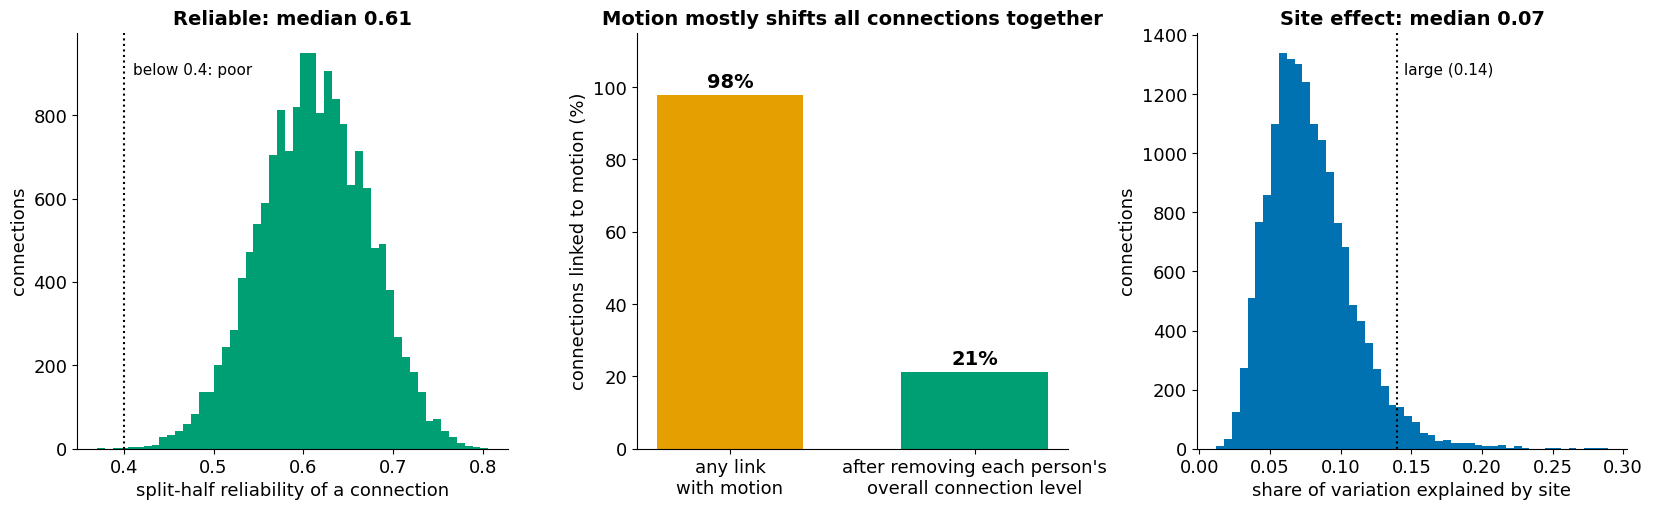

In [ ]:
# @title Figure 1. Data quality: reliability, head motion and site
print(f"atlas checks: {FL.loc['P1.atlas_files', 'result']}; region order: {FL.loc['P1.region_order', 'result']}")
flag_old = ET["flag_motion"].mean() * 100
flag_new = pd.read_csv(P38 / "6_confounds" / "edge_motion_flag_partial.csv")["flag_motion_partial"].mean() * 100
fig, axs = plt.subplots(1, 3, figsize=(20, 5.4), gridspec_kw=dict(wspace=0.3))
ax = axs[0]
ax.hist(ET["reliability"], bins=50, color=COL["green"])
ax.axvline(0.4, color="black", ls=":", lw=1.5); ax.text(0.41, ax.get_ylim()[1] * 0.9, "below 0.4: poor", fontsize=11)
ax.set_xlabel("split-half reliability of a connection"); ax.set_ylabel("connections")
ax.set_title(f"Reliable: median {ET['reliability'].median():.2f}")
ax = axs[1]
ax.bar([0, 1], [flag_old, flag_new], color=[COL["orange"], COL["green"]], width=0.6)
for k, v in enumerate([flag_old, flag_new]):
    ax.text(k, v + 2, f"{v:.0f}%", ha="center", fontsize=14, weight="bold")
ax.set_xticks([0, 1]); ax.set_xticklabels(["any link\nwith motion", "after removing each person's\noverall connection level"])
ax.set_ylim(0, 115); ax.set_ylabel("connections linked to motion (%)")
ax.set_title("Motion mostly shifts all connections together")
ax = axs[2]
ax.hist(ET["site_eta2"], bins=50, color=COL["ctrl"])
ax.axvline(0.14, color="black", ls=":", lw=1.5); ax.text(0.145, ax.get_ylim()[1] * 0.9, "large (0.14)", fontsize=11)
ax.set_xlabel("share of variation explained by site"); ax.set_ylabel("connections")
ax.set_title(f"Site effect: median {ET['site_eta2'].median():.2f}")
show_save(fig, "f1_data_quality")

 Connections are reliable (median 0.61; almost none poor). Almost every connection rises with head motion, but after removing each person's overall connection level only about a fifth still do: motion mainly lifts everything together. Site explains a modest share (median 7%).

Group comparisons below always hold site, age, sex and motion fixed, and motion is checked again in section 8.

# 3. Replication in new sites
**How it was tested.** In half A, every connection was compared between ASD and controls (holding site, age, sex and motion fixed). The candidates were then **frozen** and tested once in half B with a rule fixed in advance: same direction as in half A and one-sided p < 0.05 counts as **evidence**.

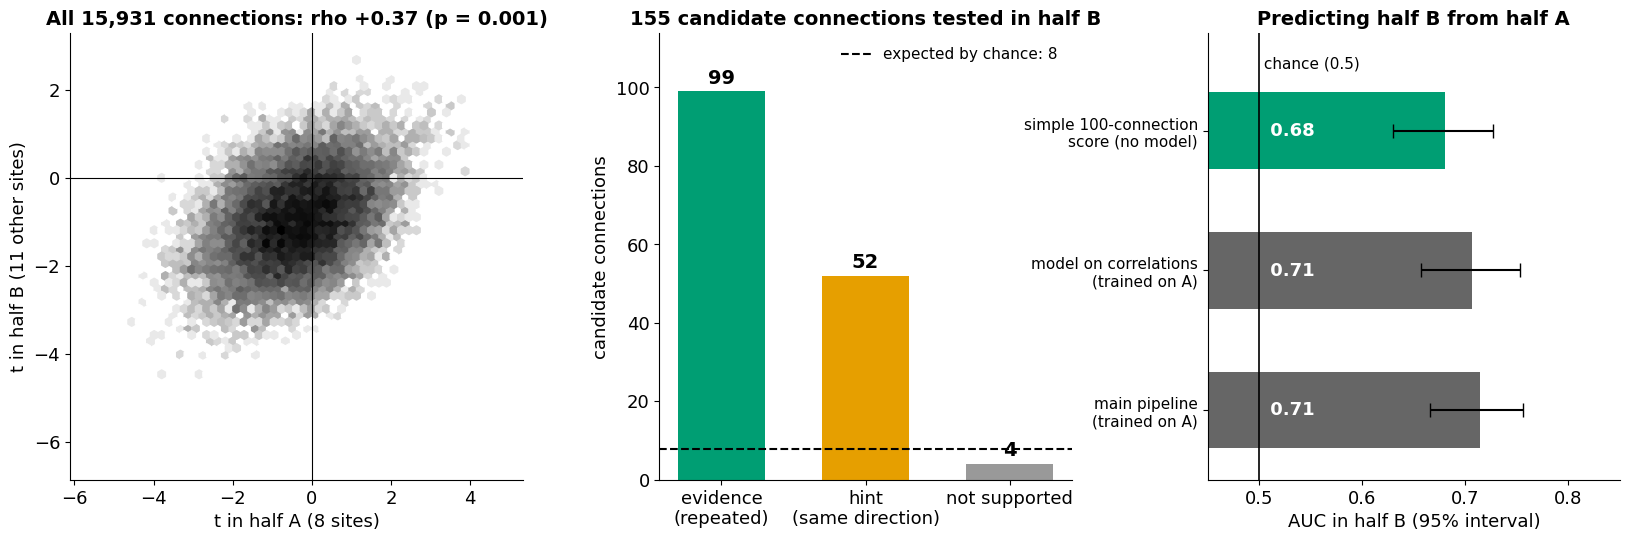

In [ ]:
# @title Figure 2. The half-A differences repeat in half B
wm = conf[conf["type"] == "whole map"].iloc[0]
ce = cf[cf["type"] == "connection"]; counts = ce["verdict"].value_counts().reindex(["evidence", "hint", "not supported"]).fillna(0)
pb = pd.read_csv(P38 / "7_confirm" / "halfB_prediction.csv")
fig, axs = plt.subplots(1, 3, figsize=(20, 5.8), gridspec_kw=dict(width_ratios=[1.1, 1, 1], wspace=0.32))
ax = axs[0]
ax.hexbin(tA, tB, gridsize=55, cmap="Greys", mincnt=1, bins="log")
ax.axhline(0, color="black", lw=0.8); ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("t in half A (8 sites)"); ax.set_ylabel("t in half B (11 other sites)")
ax.set_title(f"All {E:,} connections: rho {wm['stat_B']:+.2f} (p = {wm['p_B_one_sided']:.3f})")
ax = axs[1]
ax.bar(range(3), counts.values, color=[VERDICT_COL[k] for k in counts.index], width=0.6)
for k, v in enumerate(counts.values):
    ax.text(k, v + counts.max() * 0.02, f"{int(v)}", ha="center", fontsize=14, weight="bold")
ax.axhline(0.05 * len(ce), color="black", ls="--", lw=1.5, label=f"expected by chance: {0.05 * len(ce):.0f}")
ax.legend(frameon=False, loc="upper right"); ax.set_ylim(0, counts.max() * 1.15)
ax.set_xticks(range(3)); ax.set_xticklabels(["evidence\n(repeated)", "hint\n(same direction)", "not supported"])
ax.set_ylabel("candidate connections"); ax.set_title(f"{len(ce)} candidate connections tested in half B")
ax = axs[2]
lab = ["simple 100-connection\nscore (no model)", "model on correlations\n(trained on A)", "main pipeline\n(trained on A)"]
vals = pb["AUC"].values[:3]; ci = [interval(s) for s in pb["interval"].values[:3]]
ax.barh(range(3), vals, color=[COL["A"], COL["grey"], COL["grey"]], height=0.55)
ax.errorbar(vals, range(3), xerr=[[v - c[0] for v, c in zip(vals, ci)], [c[1] - v for v, c in zip(vals, ci)]], fmt="none", color="black", capsize=5)
for k, v in enumerate(vals):
    ax.text(0.505, k, f" {v:.2f}", va="center", ha="left", fontsize=13, weight="bold", color="white")
ax.axvline(0.5, color="black", lw=1.2); ax.text(0.5, -0.45, " chance (0.5)", fontsize=11)
ax.set_yticks(range(3)); ax.set_yticklabels(lab, fontsize=11); ax.invert_yaxis()
ax.set_xlim(0.45, max(0.85, max(c[1] for c in ci) + 0.03)); ax.set_ylim(2.5, -0.7)
ax.set_xlabel("AUC in half B (95% interval)"); ax.set_title("Predicting half B from half A")
show_save(fig, "f2_replication")

**What it shows.**
* **Left:** connections that differed in half A tend to differ the same way in half B (rho 0.37; 95% of runs with shuffled labels stayed below 0.17). The cloud sits below zero because in half B almost every connection is a little weaker in ASD; the rho measures whether the *same* connections differ most, which ignores this overall shift.
* **Middle:** 99 of 155 candidate connections repeated, where about 8 would by chance. Only 4 went the opposite way.
* **Right:** a simple score that just averages 100 half-A connections separates ASD from controls in new sites (AUC 0.68) without any machine learning. Full models trained on half A reach about 0.71.

**How sure.** This is the strongest result of the project: found in one set of hospitals, confirmed in a separate set. It is a pooled result over the 11 half-B sites, not a test of each site alone.

# 4. Connections that differ
The 99 confirmed connections are sorted into groups by the brain systems they link. A connection is "weaker in ASD" when the two regions' signals rise and fall together less in ASD than in controls.

In [ ]:
# 4. Group the confirmed connections by brain system
def theme(e):
    a, b = NET_AL[EI[e]], NET_AL[EJ[e]]; na, nb = NAME[EIo[e]], NAME[EJo[e]]
    if "Subcortical" in (a, b):
        return "Thalamus or other deep region with cortex"
    if a == b == "SomMot":
        return "Within the body-sense and movement strip"
    if "Temporal Pole" in na + nb or "Limbic" in (a, b):
        return "Temporal pole (limbic) with other areas"
    if a == b == "Default":
        return "Within the default mode network"
    if "Vis" in (a, b) or "DorsAttn" in (a, b):
        return "Visual and attention areas"
    if "SomMot" in (a, b):
        return "Body-sense and movement strip with other areas"
    return "Other"
ev = cf[(cf["type"] == "connection") & (cf["verdict"] == "evidence")].copy()
ev["theme"] = [theme(e) for e in ev["index"]]
ev["direction"] = np.where(ev["stat_A"] < 0, "weaker in ASD", "stronger in ASD")
TH = ev.groupby(["theme", "direction"]).size().unstack(fill_value=0)
for c in ["weaker in ASD", "stronger in ASD"]:
    if c not in TH:
        TH[c] = 0
TH = TH[["weaker in ASD", "stronger in ASD"]]; TH = TH.loc[TH.sum(axis=1).sort_values(ascending=False).index]
print(f"confirmed connections: {len(ev)}; weaker in ASD {(ev['stat_A'] < 0).sum()}, stronger in ASD {(ev['stat_A'] > 0).sum()}\n")
print(TH.to_string())
ex = ev.assign(absB=ev["stat_B"].abs()).sort_values("absB", ascending=False)
print("\nclearest confirmed connections in half B (t in A and in B):")
for th in TH.index:
    r = ex[ex["theme"] == th].head(2)
    for _, row in r.iterrows():
        print(f"  [{th}] {row['label']}: A {row['stat_A']:+.1f}, B {row['stat_B']:+.1f}")

confirmed connections: 99; weaker in ASD 91, stronger in ASD 8

direction                                       weaker in ASD  stronger in ASD
theme                                                                         
Within the body-sense and movement strip                   31                0
Visual and attention areas                                 21                0
Within the default mode network                            16                0
Temporal pole (limbic) with other areas                    10                0
Thalamus or other deep region with cortex                   2                8
Other                                                       9                0
Body-sense and movement strip with other areas              2                0

clearest confirmed connections in half B (t in A and in B):
  [Within the body-sense and movement strip] Postcentral Gyrus (left) and Postcentral Gyrus (left): A -3.8, B -4.5
  [Within the body-sense and movement strip] Post

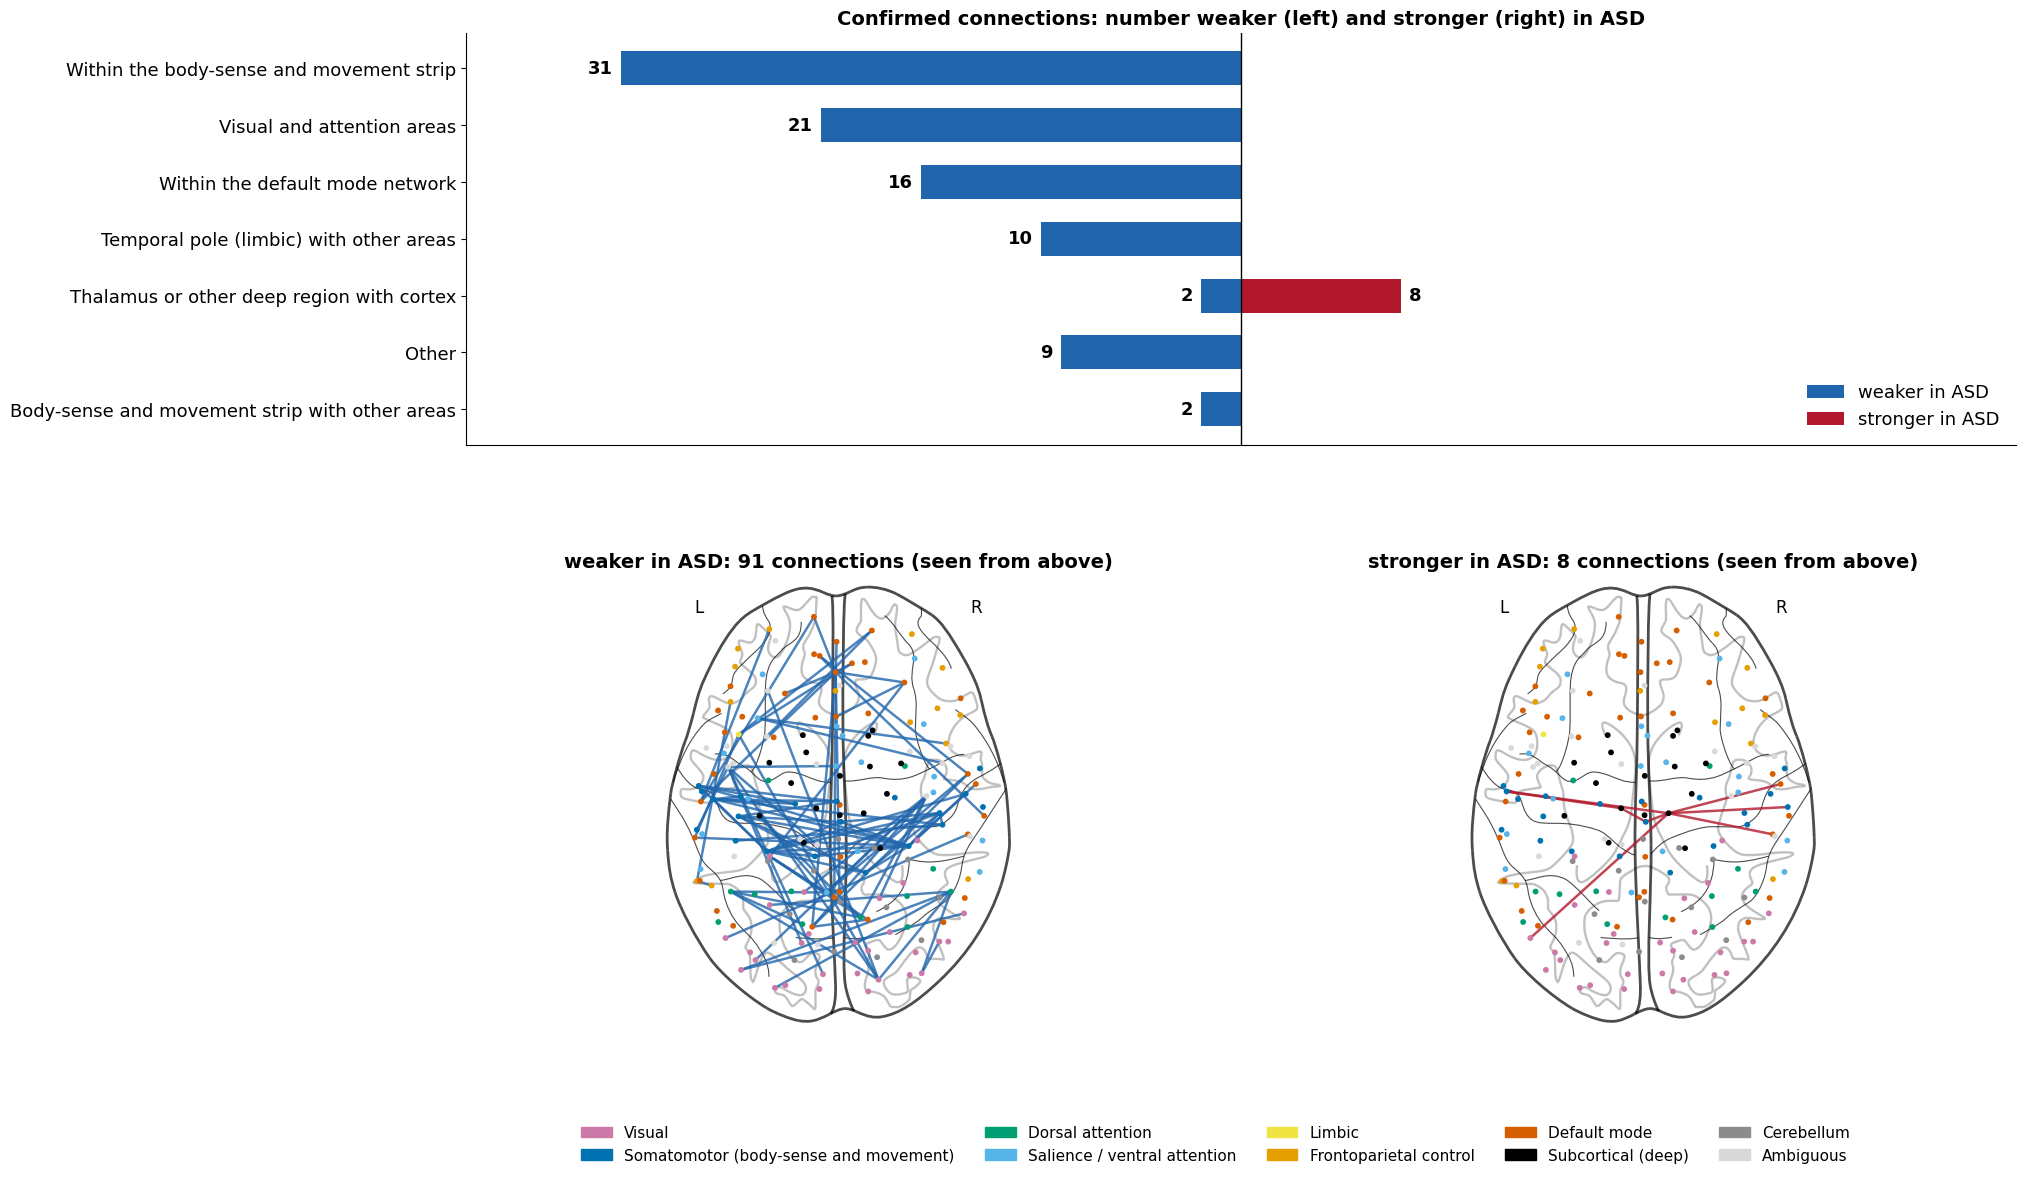

In [ ]:
# @title Figure 3. The confirmed connections by brain system and in the brain
fig = plt.figure(figsize=(20, 13))
gs = GridSpec(2, 2, figure=fig, height_ratios=[0.9, 1], hspace=0.3, wspace=0.08)
ax = fig.add_subplot(gs[0, :])
yy = np.arange(len(TH))
ax.barh(yy, -TH["weaker in ASD"].values, color=COL["weak"], height=0.6, label="weaker in ASD")
ax.barh(yy, TH["stronger in ASD"].values, color=COL["strong"], height=0.6, label="stronger in ASD")
for k, (w_, s_) in enumerate(TH.values):
    if w_: ax.text(-w_ - 0.4, k, str(w_), va="center", ha="right", fontsize=13, weight="bold")
    if s_: ax.text(s_ + 0.4, k, str(s_), va="center", ha="left", fontsize=13, weight="bold")
ax.axvline(0, color="black", lw=1); ax.set_yticks(yy); ax.set_yticklabels(TH.index, fontsize=13); ax.invert_yaxis()
m_ = TH.values.max() * 1.25; ax.set_xlim(-m_, m_)
ax.set_xticks([]); ax.legend(frameon=False, loc="lower right", fontsize=13)
ax.set_title("Confirmed connections: number weaker (left) and stronger (right) in ASD")
for k, (direction, sign, col) in enumerate([("weaker in ASD", -1, COL["weak"]), ("stronger in ASD", 1, COL["strong"])]):
    ax = fig.add_subplot(gs[1, k])
    sub = ev[np.sign(ev["stat_A"]) == sign]
    pos = {r: i for i, r in enumerate(AL)}
    adj = np.zeros((len(AL), len(AL)))
    for e in sub["index"]:
        adj[EI[e], EJ[e]] = adj[EJ[e], EI[e]] = 1
    plotting.plot_connectome(adj, xyz[AL], node_color=[GROUP_COL[g] for g in NET_AL], node_size=10,
                             edge_cmap=matplotlib.colors.ListedColormap([col, col]), edge_vmin=0, edge_vmax=1,
                             display_mode="z", axes=ax, figure=fig, colorbar=False, edge_kwargs={"linewidth": 1.8, "alpha": 0.8})
    ax.set_title(f"{direction}: {len(sub)} connections (seen from above)", fontsize=14)
fig.legend(handles=[Patch(color=GROUP_COL[g], label=GROUP_NAME[g]) for g in G_ORDER], loc="lower center", ncol=5,
           frameon=False, fontsize=11, bbox_to_anchor=(0.5, 0.0))
show_save(fig, "f3_confirmed_connections")

**What it shows.** Of the 99 confirmed connections, 91 are **weaker in ASD**, mainly:
* **inside the body-sense and movement strip** (postcentral and precentral gyrus, including left with right): 31 connections. This is the clearest result in both halves.
* **involving visual or attention areas**: 21.
* **inside the default mode network**, the front (medial frontal cortex) with the back (precuneus), a system linked to thinking about oneself and others: 16.
* **between the temporal pole and other areas**, a region linked to social and emotional knowledge: 10.

All 8 that are **stronger in ASD** link **the thalamus with the cortex**. The thalamus relays sensory information to the cortex.

**How sure.** Weaker cortical connections: strong. Stronger thalamus connections: they repeated, but more weakly (t about +2 in half B against +4 in half A), the thalamus did not pass the region-level test (section 5), and these connections are the most linked to head motion. Treat them as a lead.

**Fits with earlier work.** Large ABIDE studies also reported mostly weaker cortical connections in ASD with stronger connections between deep and sensorimotor regions (Di Martino et al., 2014; Cerliani et al., 2015).

# 5. Networks and regions
Averaging all connections between two networks gives a more stable summary than single connections. The same is done for each region (average strength of its differences, in either direction).

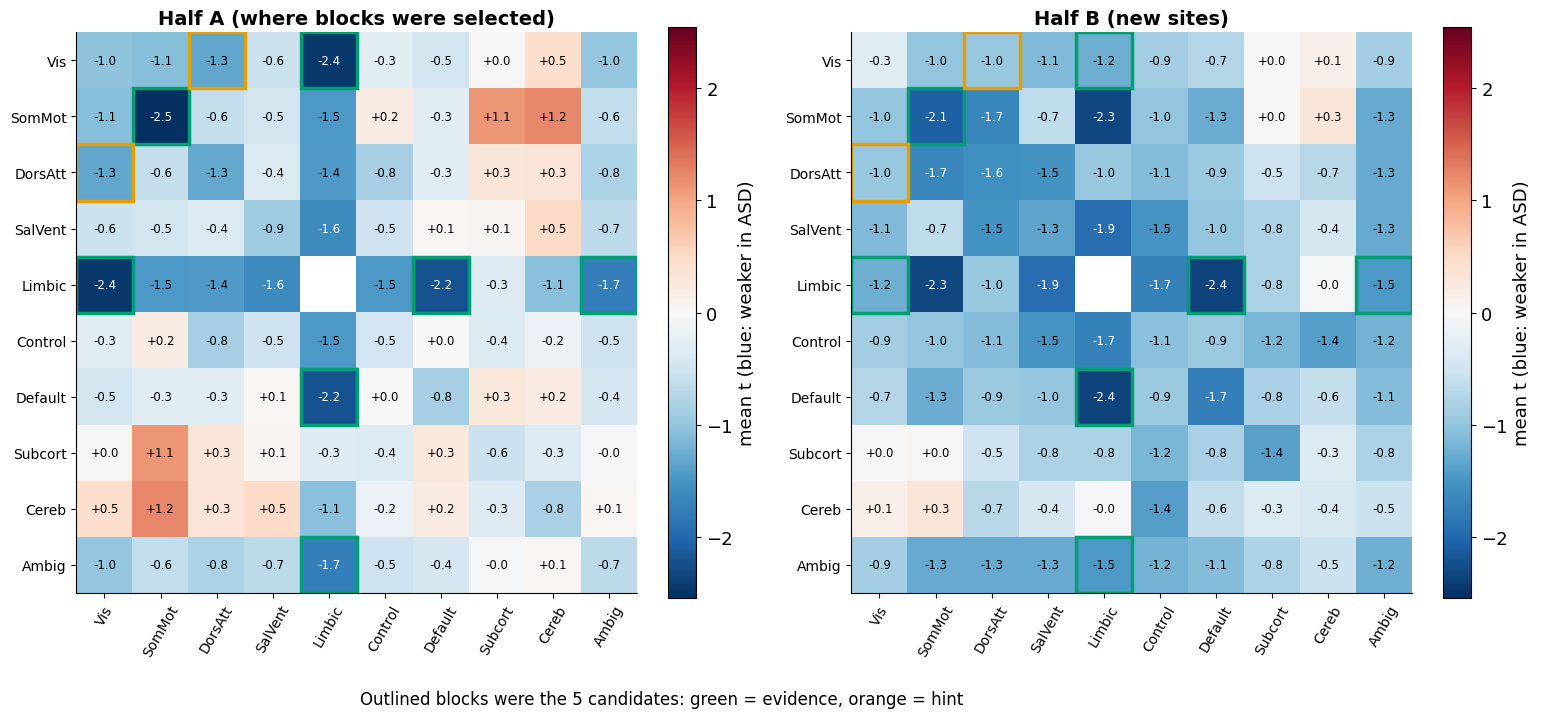

In [ ]:
# @title Figure 4A. Network blocks in half A and half B
bA, bB = tA @ B_AVG, tB @ B_AVG
def bmat(v):
    M = np.full((len(G_ORDER), len(G_ORDER)), np.nan)
    for (p, q), val in zip(BLOCKS, v):
        M[p, q] = M[q, p] = val
    return M
cb = cf[cf["type"] == "block"]
mark = {BLOCKS[i]: v for i, v in zip(cb["index"], cb["verdict"])}
fig = plt.figure(figsize=(18, 7.6))
gs = GridSpec(1, 2, figure=fig, wspace=0.25)
vm = np.nanmax(np.abs(np.r_[bA, bB]))
for k, (v, ttl) in enumerate([(bA, "Half A (where blocks were selected)"), (bB, "Half B (new sites)")]):
    ax = fig.add_subplot(gs[k]); M = bmat(v)
    im = ax.imshow(M, cmap="RdBu_r", vmin=-vm, vmax=vm)
    for (p, q), verdict in mark.items():
        for (r_, c_) in {(p, q), (q, p)}:
            ax.add_patch(plt.Rectangle((c_ - 0.5, r_ - 0.5), 1, 1, fill=False, lw=2.5, ec=VERDICT_COL[verdict]))
    for p in range(len(G_ORDER)):
        for q in range(len(G_ORDER)):
            if np.isfinite(M[p, q]):
                ax.text(q, p, f"{M[p, q]:+.1f}", ha="center", va="center", fontsize=8.5, color="white" if abs(M[p, q]) > 0.6 * vm else "black")
    ax.set_xticks(range(len(G_ORDER))); ax.set_xticklabels([GROUP_SHORT[g] for g in G_ORDER], rotation=60, fontsize=10)
    ax.set_yticks(range(len(G_ORDER))); ax.set_yticklabels([GROUP_SHORT[g] for g in G_ORDER], fontsize=10)
    ax.set_title(ttl); plt.colorbar(im, ax=ax, fraction=0.046, label="mean t (blue: weaker in ASD)")
fig.text(0.45, -0.02, "Outlined blocks were the 5 candidates: green = evidence, orange = hint", ha="center", fontsize=12)
show_save(fig, "f4_networks")

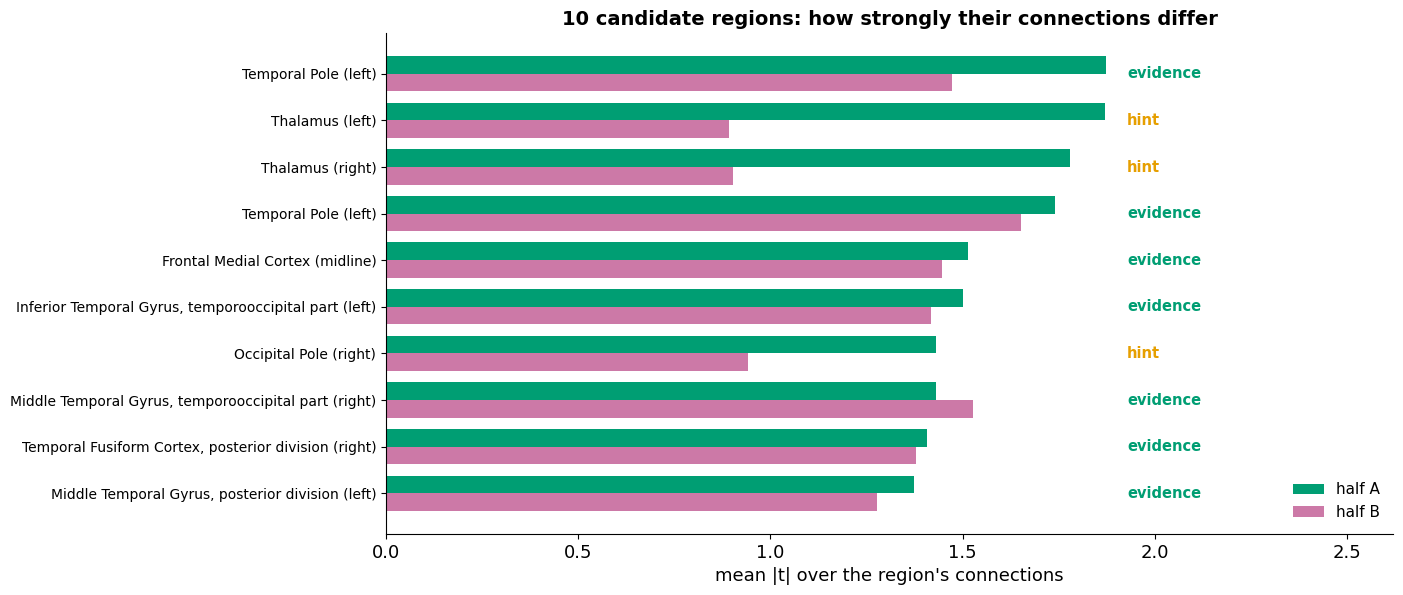

In [ ]:
# @title Figure 4B. The candidate regions in half A and half B
fig, ax = plt.subplots(figsize=(13, 6.5))
cr =cf[cf["type"] == "region"].sort_values("stat_A", ascending=False).head(12).reset_index(drop=True)
yy = np.arange(len(cr)); w = 0.38
ax.barh(yy - w / 2, cr["stat_A"], w, color=COL["A"], label="half A")
ax.barh(yy + w / 2, cr["stat_B"], w, color=COL["B"], label="half B")
for k, v in enumerate(cr["verdict"]):
    ax.text(max(cr["stat_A"].max(), cr["stat_B"].max()) * 1.03, k, v, va="center", fontsize=10.5, color=VERDICT_COL[v], weight="bold")
ax.set_yticks(yy); ax.set_yticklabels([re.sub(r"^\d+: ", "", l) for l in cr["label"]], fontsize=10); ax.invert_yaxis()
ax.set_xlim(0, max(cr["stat_A"].max(), cr["stat_B"].max()) * 1.4)
ax.set_xlabel("mean |t| over the region's connections"); ax.legend(frameon=False, loc="lower right")
ax.set_title(f"{len(cr)} candidate regions: how strongly their connections differ")
show_save(fig, "f4b_regions")

**What it shows.**
* **Networks:** four of the five candidate blocks repeated: connections **within the somatomotor network**, and between the **limbic** network (temporal pole) and the default mode, visual and other areas. In both halves the cortex is mostly blue (weaker in ASD). In half A, subcortical and cerebellar connections with the somatomotor network are red (stronger), but in half B they are close to zero, so at the network level that part did not clearly repeat. Half B is also bluer overall: there, ASD connectivity is a little weaker almost everywhere.
* **Regions:** 7 of 10 candidate regions repeated: the left **temporal pole** (two regions), the **medial frontal cortex**, and several **temporal** regions (middle and inferior temporal, fusiform). The two thalamus regions and the occipital pole were only hints.

**How sure.** Blocks and regions: evidence by the fixed rule. No single region stood out strongly on its own in half A, so the signal is spread over many regions rather than concentrated in one spot.

# 6. What the model uses
The model's weights were turned into **patterns** (Haufe et al., 2014): for each connection, how strongly it goes up and down with the model's ASD score. Weights alone can be misleading, because the model also uses connections that only cancel noise.

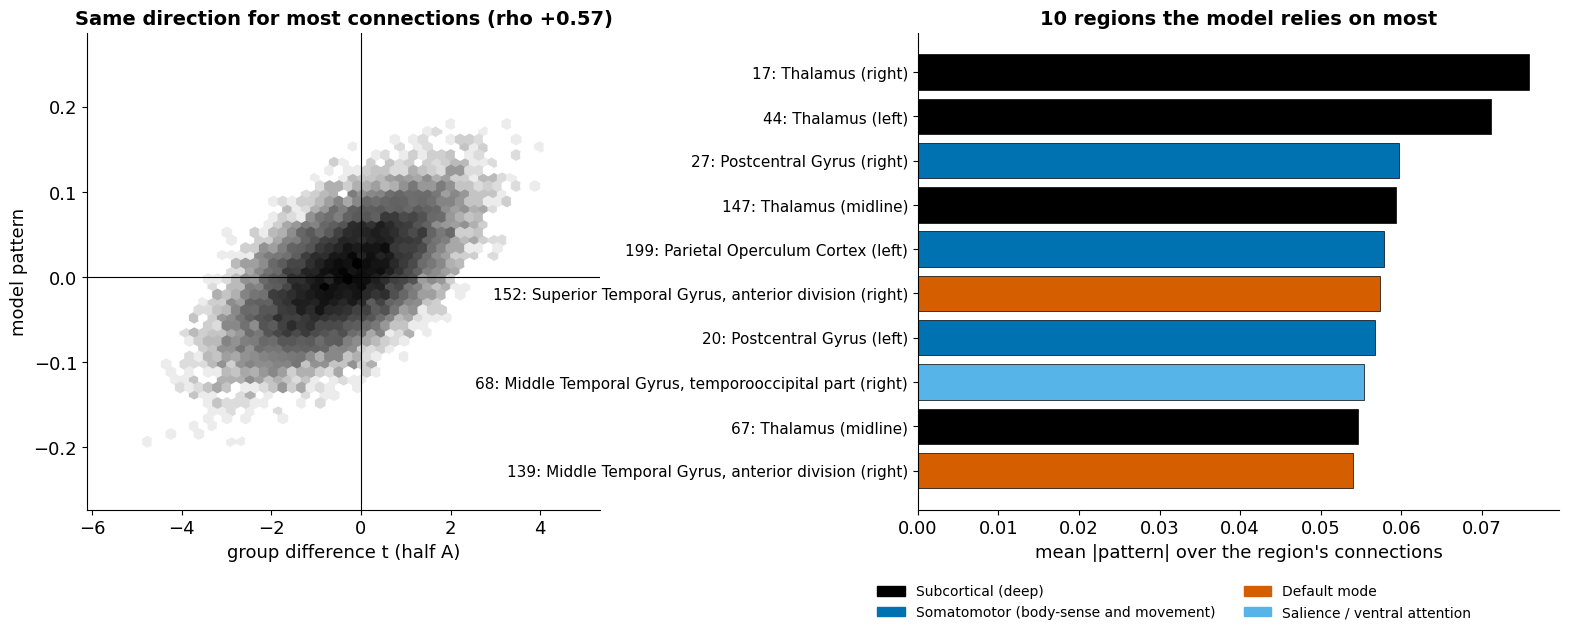

In [ ]:
# @title Figure 5. The model's pattern compared with the group differences
mp = pd.read_csv(P38 / "4_model" / "model_pattern_edges.csv"); mr = pd.read_csv(P38 / "4_model" / "model_pattern_regions.csv")
rho = spearmanr(mp["pattern"], tA).correlation
fig, axs = plt.subplots(1, 2, figsize=(19, 6.2), gridspec_kw=dict(width_ratios=[1, 1.25], wspace=0.55))
ax = axs[0]
ax.hexbin(tA, mp["pattern"], gridsize=50, cmap="Greys", mincnt=1, bins="log")
ax.axhline(0, color="black", lw=0.8); ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("group difference t (half A)"); ax.set_ylabel("model pattern")
ax.set_title(f"Same direction for most connections (rho {rho:+.2f})")
ax = axs[1]
top = mr.sort_values("mean_abs_pattern", ascending=False).head(10)
ax.barh(range(10), top["mean_abs_pattern"], color=[GROUP_COL[g] for g in top["network"]], edgecolor="black", lw=0.5)
ax.set_yticks(range(10)); ax.set_yticklabels([f"{r}: {n}" for r, n in zip(top["region"], top["name"])], fontsize=11); ax.invert_yaxis()
ax.set_xlabel("mean |pattern| over the region's connections")
ax.legend(handles=[Patch(color=GROUP_COL[g], label=GROUP_NAME[g]) for g in dict.fromkeys(top["network"])], frameon=False, fontsize=10, loc="upper center", bbox_to_anchor=(0.4, -0.13), ncol=2)
ax.set_title("10 regions the model relies on most")
show_save(fig, "f5_model_pattern")

**What it shows.** The model's pattern follows the group differences (rho 0.57). The regions it relies on most are the **thalamus** (left, right and midline) and the **postcentral gyrus**, the same systems as in sections 3 and 4.

**How sure.** Descriptive: the model was trained on all sites, so this is not an independent test. Its strong reliance on thalamus connections, which are the most motion-linked, is one reason the model's output still correlates a little with motion (main notebook).

# 7. A pattern shared across ASD participants
Two views:
* **Model scores.** If only a small subgroup carried the signal, most ASD participants would score like controls.
* **Similarity between people** (half A, after removing site, age, sex and motion). If ASD participants share a pattern, two ASD participants are more alike than an ASD participant and a control.

shared pattern (ASD-ASD minus ASD-control): +0.0053, p = 0.002
more variable in ASD (control-control minus ASD-ASD): -0.0000, p = 1.000


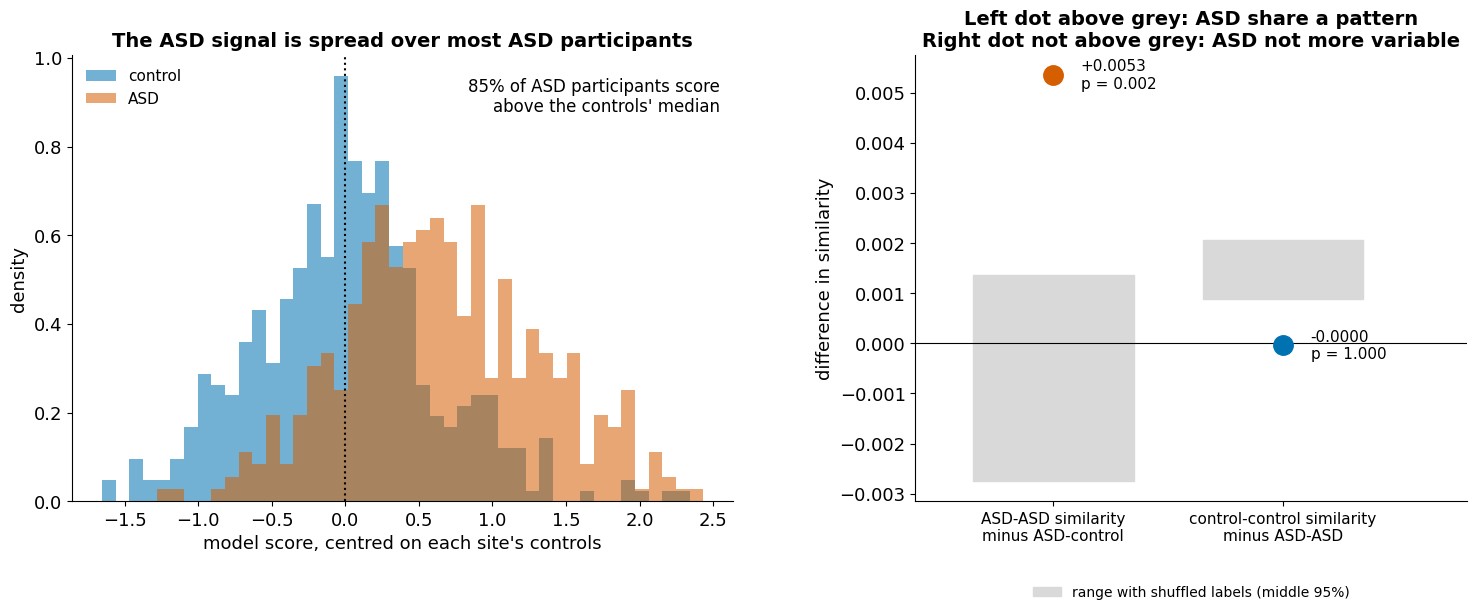

In [ ]:
# @title Figure 6. Model scores of all participants and similarity between participants
SC = SCORE.copy()
for s_ in np.unique(site):
    i = site == s_; SC[i] = SCORE[i] - np.median(SCORE[i & (y == 0)])
share = np.mean(SC[y == 1] > np.median(SC[y == 0]))
sim = pd.read_csv(P38 / "5_shared" / "similarity_halfA.csv").set_index("measure")
fig, axs = plt.subplots(1, 2, figsize=(18, 5.8), gridspec_kw=dict(width_ratios=[1.2, 1], wspace=0.3))
ax = axs[0]
bins = np.linspace(np.percentile(SC, 0.5), np.percentile(SC, 99.5), 45)
ax.hist(SC[y == 0], bins=bins, color=COL["ctrl"], alpha=0.55, density=True, label="control")
ax.hist(SC[y == 1], bins=bins, color=COL["asd"], alpha=0.55, density=True, label="ASD")
ax.axvline(0, color="black", ls=":", lw=1.5)
ax.text(0.98, 0.95, f"{share:.0%} of ASD participants score\nabove the controls' median", transform=ax.transAxes, ha="right", va="top", fontsize=12)
ax.set_xlabel("model score, centred on each site's controls"); ax.set_ylabel("density"); ax.legend(frameon=False, loc="upper left")
ax.set_title("The ASD signal is spread over most ASD participants")
ax = axs[1]
keys = ["shared (AA - AC)", "idiosyncrasy (CC - AA)"]
labs = ["ASD-ASD similarity\nminus ASD-control", "control-control similarity\nminus ASD-ASD"]
for k, kk in enumerate(keys):
    lo_, hi_ = interval(sim.loc[kk, "shuffles middle 95%"])
    ax.add_patch(plt.Rectangle((k - 0.35, lo_), 0.7, hi_ - lo_, color=COL["light"], zorder=1))
    ax.plot(k, sim.loc[kk, "real"], "o", ms=14, color=[COL["asd"], COL["ctrl"]][k], zorder=3)
    ax.text(k + 0.12, sim.loc[kk, "real"], f"{sim.loc[kk, 'real']:+.4f}\np = {sim.loc[kk, 'p (real above shuffles)']:.3f}", va="center", fontsize=11)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(2)); ax.set_xticklabels(labs, fontsize=11); ax.set_xlim(-0.6, 1.8)
ax.set_ylabel("difference in similarity")
ax.legend(handles=[Patch(color=COL["light"], label="range with shuffled labels (middle 95%)")], frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), fontsize=10)
ax.set_title("Left dot above grey: ASD share a pattern\nRight dot not above grey: ASD not more variable")
print(f"shared pattern (ASD-ASD minus ASD-control): {sim.loc['shared (AA - AC)', 'real']:+.4f}, p = {sim.loc['shared (AA - AC)', 'p (real above shuffles)']:.3f}")
print(f"more variable in ASD (control-control minus ASD-ASD): {sim.loc['idiosyncrasy (CC - AA)', 'real']:+.4f}, p = {sim.loc['idiosyncrasy (CC - AA)', 'p (real above shuffles)']:.3f}")

**What it shows.**
* **Left:** 85% of ASD participants score above the controls' median (50% would mean no difference), so the signal is spread over most ASD participants, not carried by a small group.
* **Right:** two ASD participants are more alike than an ASD participant and a control (orange dot far above the grey band, p = 0.002). Control pairs and ASD pairs are equally alike (blue dot not above the grey band), so ASD participants are not more variable than controls. In other words, ASD shares a common shift in connectivity rather than each person differing in their own way.

**How sure.** Hint (half A only, not re-tested in half B). The similarities are tiny numbers because most of each connectome is individual; the comparison between pair types is what matters.

**Subgroups.** A search for distinct ASD subgroups found nothing convincing (controls clustered almost as well), so it is left out here.

# 8. Robustness: motion, site and participant groups
Three alternative explanations are checked:
* **Head motion.** ASD participants moved more, so the half-A map is recomputed with low-motion participants only.
* **One large site.** NYU has 172 of the 414 half-A participants, so the map is recomputed leaving out each half-A site in turn.
* **Participant groups.** The model's AUC is computed separately by age group, sex, eye status and diagnostic subtype.

In [ ]:
# 8. Low-motion check: half-A map using only participants with mean FD below 0.2 mm, against random subsets of the same size
low = A_IDX[fd[A_IDX] < 0.2]
r_low = spearmanr(t_map(low), tA).correlation
rng = np.random.default_rng(0)
r_rand = [spearmanr(t_map(np.sort(rng.choice(A_IDX, len(low), replace=False))), tA).correlation for _ in range(20)]
losa = pd.read_csv(P38 / "6_confounds" / "leave_one_site_out_halfA.csv")
print(f"low-motion participants: {len(low)} of {len(A_IDX)}; agreement with the full map {r_low:.3f}; "
      f"random subsets {min(r_rand):.3f} to {max(r_rand):.3f}")
print(losa.to_string(index=False))

low-motion participants: 371 of 414; agreement with the full map 0.959; random subsets 0.964 to 0.977
site left out  participants left out  agreement with full map (rho)  connections p < 0.001  q < 0.05
          CMU                     11                          0.992                    203       113
          KKI                     33                          0.980                    272       223
     LEUVEN_2                     28                          0.982                    157        66
          NYU                    172                          0.870                     77         1
         OLIN                     28                          0.978                    201       114
         PITT                     50                          0.947                    215        82
     STANFORD                     25                          0.981                    268       207
          USM                     67                          0.961                    124

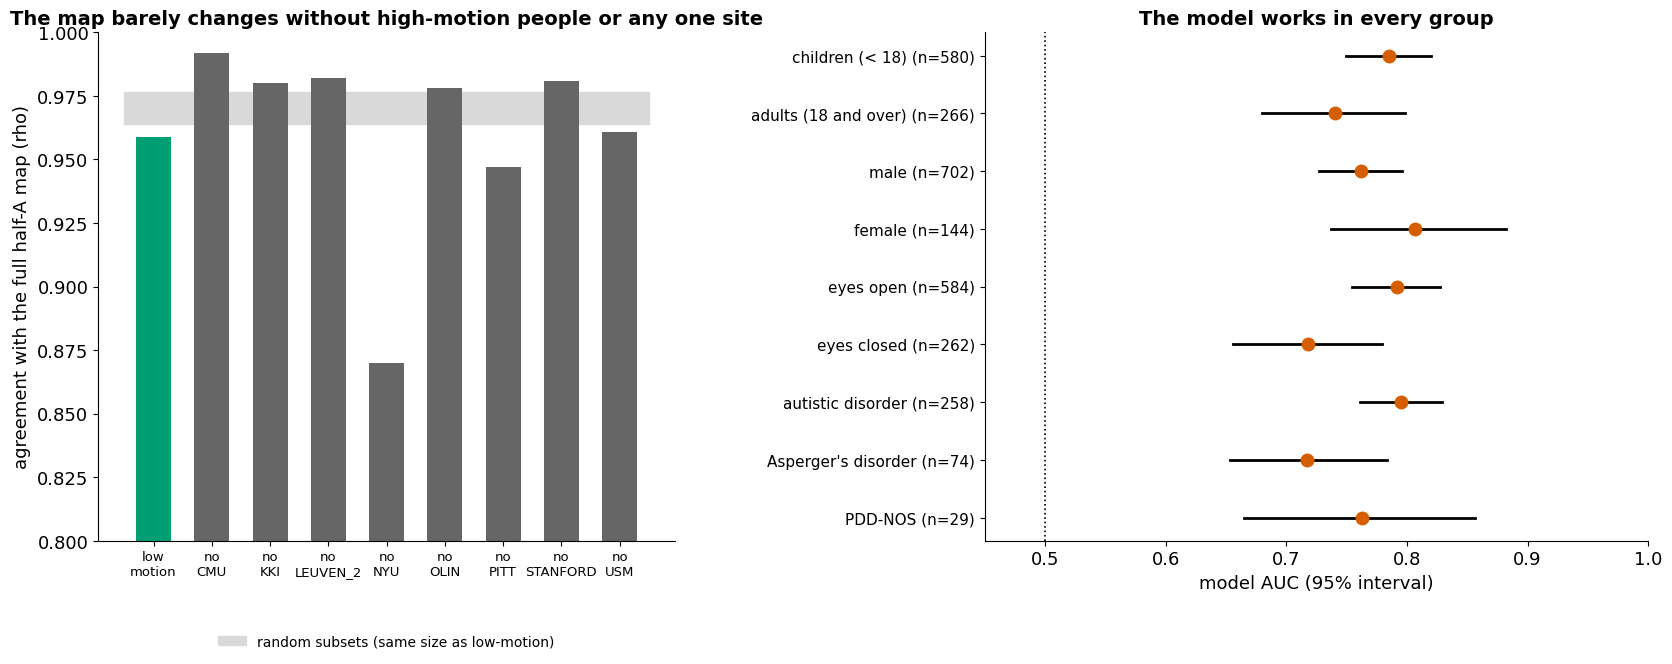

In [ ]:
# @title Figure 7. Robustness checks
ag = pd.read_csv(P38 / "6_confounds" / "age_groups.csv"); sg = pd.read_csv(P38 / "6_confounds" / "subgroup_auc.csv")
st = pd.read_csv(P38 / "5_shared" / "subtype_auc.csv").dropna(subset=["AUC"])
rows = [(r["group"], r["AUC (site-centred scores)"], r["95% interval"], r["n"]) for _, r in ag.iterrows()]
rows += [(r["subgroup"], r["AUC"], r["95% interval"], r["n"]) for _, r in sg.iterrows()]
rows += [(r["subtype"], r["AUC"], r["95% interval"], int(r["ASD n"])) for _, r in st.iterrows()]
fig, axs = plt.subplots(1, 2, figsize=(20, 6.6), gridspec_kw=dict(width_ratios=[1, 1.15], wspace=0.5))
ax = axs[0]
labels_ = ["low\nmotion"] + [f"no\n{s_}" for s_ in losa["site left out"]]
vals_ = [r_low] + list(losa["agreement with full map (rho)"])
ax.fill_between([-0.5, len(vals_) - 0.5], min(r_rand), max(r_rand), color=COL["light"], label="random subsets (same size as low-motion)")
ax.bar(range(len(vals_)), vals_, color=[COL["green"]] + [COL["grey"]] * len(losa), width=0.6)
ax.set_xticks(range(len(vals_))); ax.set_xticklabels(labels_, fontsize=9.5)
ax.set_ylim(min(0.8, min(vals_) - 0.03), 1.0); ax.set_ylabel("agreement with the full half-A map (rho)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), fontsize=10); ax.set_title("The map barely changes without high-motion people or any one site")
ax = axs[1]
for k, (lab, auc, iv, n) in enumerate(rows):
    lo_, hi_ = interval(iv)
    ax.plot([lo_, hi_], [k, k], color="black", lw=2); ax.plot(auc, k, "o", color=COL["asd"], ms=9)
ax.axvline(0.5, color="black", ls=":", lw=1.2)
ax.set_yticks(range(len(rows))); ax.set_yticklabels([f"{lab} (n={n})" for lab, _, _, n in rows], fontsize=11); ax.invert_yaxis()
ax.set_xlabel("model AUC (95% interval)"); ax.set_xlim(0.45, 1.0); ax.set_title("The model works in every group")
show_save(fig, "f7_robustness")

**What it shows.**
* **Motion:** using only low-motion participants (371 of 414) still gives almost the same map (agreement 0.96). It is slightly below random subsets of the same size (0.964 to 0.977), so the high-motion participants have a small influence on the map, but motion does not create the pattern.
* **Sites:** leaving out any one half-A site barely changes the map. Without NYU it changes most (0.87), because NYU is 40% of half A, but half B has no NYU and still confirmed the pattern.
* **Groups:** the model works for children (AUC 0.79) and adults (0.74), males (0.76) and females (0.81), and all three diagnostic subtypes; weakest for Asperger's disorder (0.72) and eyes-closed scans (0.72). The intervals overlap, so these differences are not established.

**How sure.** Motion and site: strong reassurance for the cortical findings. The thalamus connections remain the most motion-linked.

# 9. Symptoms and IQ
The model score is correlated with symptom scores (ADOS, ADI-R, SRS) and IQ, separately in ASD participants and controls, and within each site, because sites used different test versions.

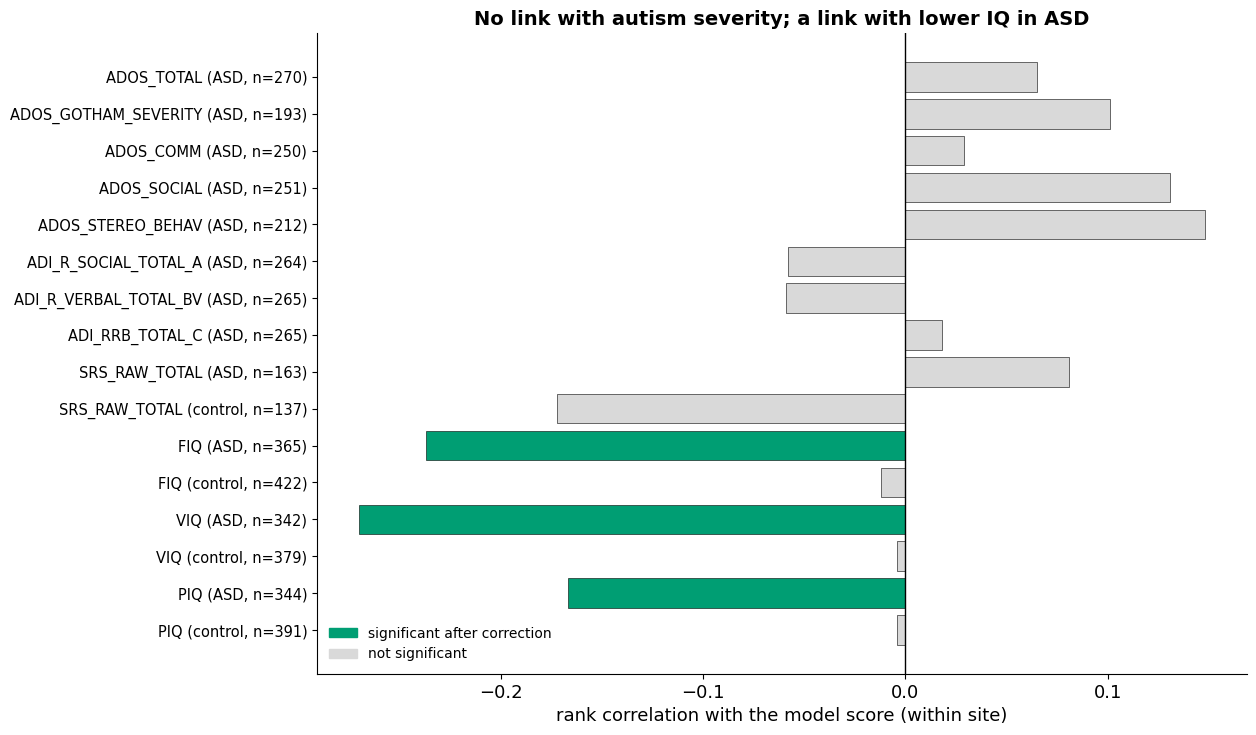

In [ ]:
# @title Figure 8. Model score against symptom scores and IQ
sv = pd.read_csv(P38 / "5_shared" / "severity_correlations.csv")
sv = sv.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 0.42 * len(sv) + 1.6))
cols_ = [COL["green"] if q < 0.05 else COL["light"] for q in sv["q"]]
ax.barh(range(len(sv)), sv["rho"], color=cols_, edgecolor="black", lw=0.4)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(range(len(sv))); ax.set_yticklabels([f"{m} ({g}, n={n})" for m, g, n in zip(sv["measure"], sv["group"], sv["n"])], fontsize=10.5)
ax.set_xlabel("rank correlation with the model score (within site)")
ax.legend(handles=[Patch(color=COL["green"], label="significant after correction"), Patch(color=COL["light"], label="not significant")],
          frameon=False, loc="lower left", fontsize=10)
ax.set_title("No link with autism severity; a link with lower IQ in ASD")
show_save(fig, "f8_symptoms")

**What it shows.** The model score does **not** clearly follow autism severity: the ADOS, ADI-R and SRS correlations are small in ASD participants (at most 0.15) and none survives correction for testing 16 measures. It does follow **lower IQ in ASD participants** (verbal IQ rho -0.27, full-scale -0.24), but not in controls.

**What it might mean.** The connectivity difference marks the diagnosis group rather than how severe symptoms are. It may be stronger in ASD participants with lower IQ, or IQ-related differences may be part of what separates the groups. This cannot be untangled with these data.

# 10. Summary

| Finding | Label | Meaning |
|---|---|---|
| ASD and controls differ in connectivity, and the half-A pattern repeats in 11 new sites | **evidence** | the signal is real, not chance or a quirk of some hospitals |
| Weaker connections within the body-sense and movement strip | **evidence** | clearest single finding; fits the sensory and motor differences common in autism |
| Weaker default mode (front with back) and temporal pole connections | **evidence** | systems linked to social thinking and social knowledge |
| Stronger thalamus with cortex connections | **evidence, weaker** | the sensory relay is more in sync with the cortex; most affected by motion |
| The model relies on the same connections | descriptive | the model learned brain differences, not a shortcut |
| ASD participants share the pattern; not more variable | hint | a common shift rather than individual differences |
| Not explained by motion, one site, age or sex | checks | the cortical findings are robust |
| No link with severity; link with lower IQ in ASD | hint | marks the diagnosis group, not symptom severity |

### Limits
* Each connection differs only a little (largest effect d about 0.56; for example r 0.60 in ASD against 0.66 in controls). The model works by combining thousands of small differences and cannot diagnose a person on its own.
* Resting-state data show **where** connectivity differs, not **why**, and not whether it causes or follows autism traits.
* ABIDE I is mostly male, aged 7 to 64, and every site used its own scanner and protocol.
* The confirmation in half B is pooled over its 11 sites; small sites are too noisy to test alone.

### Next steps
* Test the thalamus finding with stronger motion correction.
* Repeat the analysis in an independent dataset (for example ABIDE II).
* Relate the sensorimotor finding to measures of sensory sensitivity.

# References
* Cerliani, L., Mennes, M., Thomas, R. M., Di Martino, A., Thioux, M., & Keysers, C. (2015). Increased functional connectivity between subcortical and cortical resting-state networks in autism spectrum disorder. *JAMA Psychiatry*, 72(8), 767-777. https://doi.org/10.1001/jamapsychiatry.2015.0101
* Di Martino, A., Yan, C.-G., Li, Q., et al. (2014). The autism brain imaging data exchange: towards a large-scale evaluation of the intrinsic brain architecture in autism. *Molecular Psychiatry*, 19(6), 659-667. https://doi.org/10.1038/mp.2013.78
* Haufe, S., Meinecke, F., Görgen, K., Dähne, S., Haynes, J.-D., Blankertz, B., & Bießmann, F. (2014). On the interpretation of weight vectors of linear models in multivariate neuroimaging. *NeuroImage*, 87, 96-110. https://doi.org/10.1016/j.neuroimage.2013.10.067
* Kriegeskorte, N., Simmons, W. K., Bellgowan, P. S. F., & Baker, C. I. (2009). Circular analysis in systems neuroscience: the dangers of double dipping. *Nature Neuroscience*, 12(5), 535-540. https://doi.org/10.1038/nn.2303


Methods behind each number (reliability, motion, site effect, networks, permutation tests, confirmation rule) are described and referenced in the two exploration notebooks.